In [1]:
suppressMessages({
library(RNetCDF)
library(dplyr)
library(ggplot2)
library(parallel)
library(dataRetrieval)
library(arrow)
library(lubridate)
library(tidyr)
library(broom)
library(IRdisplay)
library(data.table)})

source('/nas/cee-water/cjgleason/colin/Batesian_Validation/Prepare_data.R')
source('/nas/cee-water/cjgleason/colin/Batesian_Validation/validate.R')


In [2]:
make_SOS_df=0
make_model_df =0
make_USGS_df = 0


runID <- 'Heejin_v5'
algos_we_want <- c("metroman", "busboi", "sic4dvar", "momma", "sad", "consensus")

USGS_df <- get_USGS(make_USGS_df, paste0(base, 'USGS data/'), paste0(base, 'USGS.parquet'))

xwalk <- make_xwalk(paste0(base, 'OG attempt/ADCP_compiled.csv'))

sos_hydrographs <- get_SOS(make_SOS_df,
  '/nas/cee-water/cjgleason/heejin/SWOT_Confluence/run-confluence/confluence_RF_consensus/RF_consensus_mnt/output_bugfix/sos/',
  algos_we_want, paste0(base, 'sos_hydrographs_', runID, '.parquet'))

model_hydrographs <- get_models(make_model_df, xwalk,
  '/nas/cee-water/cjgleason/colin/SWOT_global_Q_paper/daily_ensembles_versionD/',
  paste0(base, 'model_hydrographs_', runID, '.parquet'), n_cores = 20)

In [3]:
#match SWOT to the nearest 15 minutes and validate against Q_approved
sos_approvedQ_15min <- xwalk %>%
  right_join(sos_hydrographs, by = "reach_id", relationship = "one-to-many") %>%
  mutate(sos_row = row_number(),
         lo = time - minutes(30),
         hi = time + minutes(30)) %>%

  inner_join(USGS_df %>%
               filter(!is.na(Q_approved)) %>%
               select(USGS_ID, usgs_time = time, Q_approved, Q_lower, Q_upper),
             by = join_by(USGS_ID, between(y$usgs_time, x$lo, x$hi))) %>%

  mutate(dt_min = abs(as.numeric(difftime(time, usgs_time, units = "mins")))) %>%
  arrange(sos_row, dt_min) %>%
  distinct(sos_row, .keep_all = TRUE) %>%
  select(-sos_row, -lo, -hi)



In [4]:
options(repr.plot.width = 12, repr.plot.height = 10)
# source('/nas/cee-water/cjgleason/colin/Batesian_Validation/batesian_schematic.R')
# source('/nas/cee-water/cjgleason/colin/Batesian_Validation/bcorr_schematic.R')


In [5]:
#function takes a list of algorithm names that we want
#the validate algo function declared by sourcing validate.R
#a dataframe that has joined what we want to validate to the truth source we want, already processed
#to be 'neat'
#and a trut column
#ht ename mapping xwalk dataframe
source('/nas/cee-water/cjgleason/colin/Batesian_Validation/validate.R')
val_type <- "trad"
truth_type = 'A15'

sos_tradval_approvedQ_15min <- do.call(rbind, lapply(algos_we_want, validate_algo,
                                                      joined_df = sos_approvedQ_15min,
                                                      truth_col = "Q_approved",
                                                      lower_col = "Q_lower",
                                                      upper_col = "Q_upper",
                                                      xwalk     = xwalk,
                                                      val_type  = val_type,
                                                     truth_type=truth_type))

In [6]:

source('/nas/cee-water/cjgleason/colin/Batesian_Validation/validate.R')
val_type <- "Batesian"
truth_type <- "A15"

sos_batesval_approvedQ_15min <- do.call(rbind, lapply(algos_we_want, validate_algo,
                                                      joined_df  = sos_approvedQ_15min,
                                                      truth_col  = "Q_approved",
                                                      lower_col  = "Q_lower",
                                                      upper_col  = "Q_upper",
                                                      xwalk      = xwalk,
                                                      val_type   = val_type,
                                                      truth_type = truth_type))

In [7]:
sos_val_approvedQ_15min <- full_join(sos_tradval_approvedQ_15min,
                                     sos_batesval_approvedQ_15min,
                                     by = c("reach_id", "USGS_ID", "algo", "type"),
                                     relationship = "one-to-one")
sos_rank_approvedQ_15min <- rank_algos(sos_val_approvedQ_15min)

In [8]:
# fixed anonymization: never changes with a seed
algo_key <- tibble(algo  = c("metroman", "sad", "consensus", "momma", "busboi", "sic4dvar"),
                   model = c("A",        "B",   "C",         "D",     "E",      "F"))

rank_tables <- sos_rank_approvedQ_15min %>%
  left_join(algo_key, by = "algo", relationship = "many-to-one") %>%
  mutate(cell   = sprintf("%.3f (%s)", value, rank),
         metric = factor(metric, levels = unique(metric))) %>%
  arrange(metric) %>%
  select(USGS_ID, model, metric, cell) %>%
  pivot_wider(names_from = metric, values_from = cell) %>%
  arrange(USGS_ID, model)

for (g in unique(rank_tables$USGS_ID)) {
  cat("\n", g, "\n")
  IRdisplay::display(rank_tables %>% filter(USGS_ID == g) %>% select(-USGS_ID))
}

model,r,Rsq,NSE,KGE,RMSE,nRMSE,nBIAS,abs_nBIAS,Accuracy,Miss_bias,Miss_magnitude,Bcorr_rho0,Bcorr_rho08
<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>
B,0.802 (5),0.643 (5),0.575 (5),0.506 (4),21.298 (5),0.656 (5),-0.089 (5),0.089 (5),0.613 (3),0.129 (1),0.750 (5),0.700 (3),0.467 (4)
C,0.951 (3),0.904 (3),0.728 (3),0.529 (3),17.035 (3),0.525 (3),-0.037 (2),0.037 (2),0.581 (4),0.226 (2),0.671 (3),0.700 (3),0.467 (4)
D,0.933 (3),0.870 (4),0.695 (4),0.510 (4),18.047 (4),0.556 (4),-0.043 (2),0.043 (2),0.581 (4),0.226 (2),0.584 (1),0.700 (3),0.533 (2)
E,0.986 (1),0.972 (1),0.816 (2),0.590 (2),14.137 (2),0.449 (2),-0.061 (2),0.061 (2),0.783 (1),0.217 (2),0.624 (2),0.773 (2),0.500 (3)
F,0.985 (1),0.970 (1),0.914 (1),0.748 (1),9.588 (1),0.295 (1),-0.012 (1),0.012 (1),0.742 (2),0.258 (5),0.707 (4),0.900 (1),0.600 (1)


model,r,Rsq,NSE,KGE,RMSE,nRMSE,nBIAS,abs_nBIAS,Accuracy,Miss_bias,Miss_magnitude,Bcorr_rho0,Bcorr_rho08
<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>
A,0.944 (3),0.891 (3),0.833 (1),0.772 (1),27.885 (1),0.336 (1),-0.193 (1),0.193 (1),0.519 (1),-0.365 (1),0.493 (3),0.471 (6),0.196 (6)
B,0.913 (6),0.833 (6),0.741 (4),0.675 (2),41.728 (4),0.462 (4),0.267 (2),0.267 (2),0.376 (4),0.532 (2),0.440 (1),0.731 (3),0.481 (3)
C,0.961 (1),0.924 (1),0.793 (2),0.636 (3),37.144 (2),0.411 (2),0.275 (2),0.275 (2),0.418 (2),0.582 (3),0.502 (5),0.771 (2),0.523 (1)
D,0.921 (3),0.849 (4),0.701 (5),0.640 (3),44.490 (5),0.498 (5),0.348 (4),0.348 (4),0.394 (3),0.587 (3),0.481 (3),0.722 (3),0.324 (5)
E,0.931 (3),0.868 (4),0.660 (6),0.514 (6),49.906 (6),0.553 (6),0.362 (6),0.362 (6),0.351 (6),0.595 (3),0.606 (6),0.699 (5),0.397 (4)
F,0.971 (1),0.942 (1),0.796 (2),0.637 (3),36.879 (2),0.408 (2),0.325 (4),0.325 (4),0.364 (5),0.636 (6),0.453 (2),0.862 (1),0.532 (1)



 USGS-01048000 

 USGS-01318500 


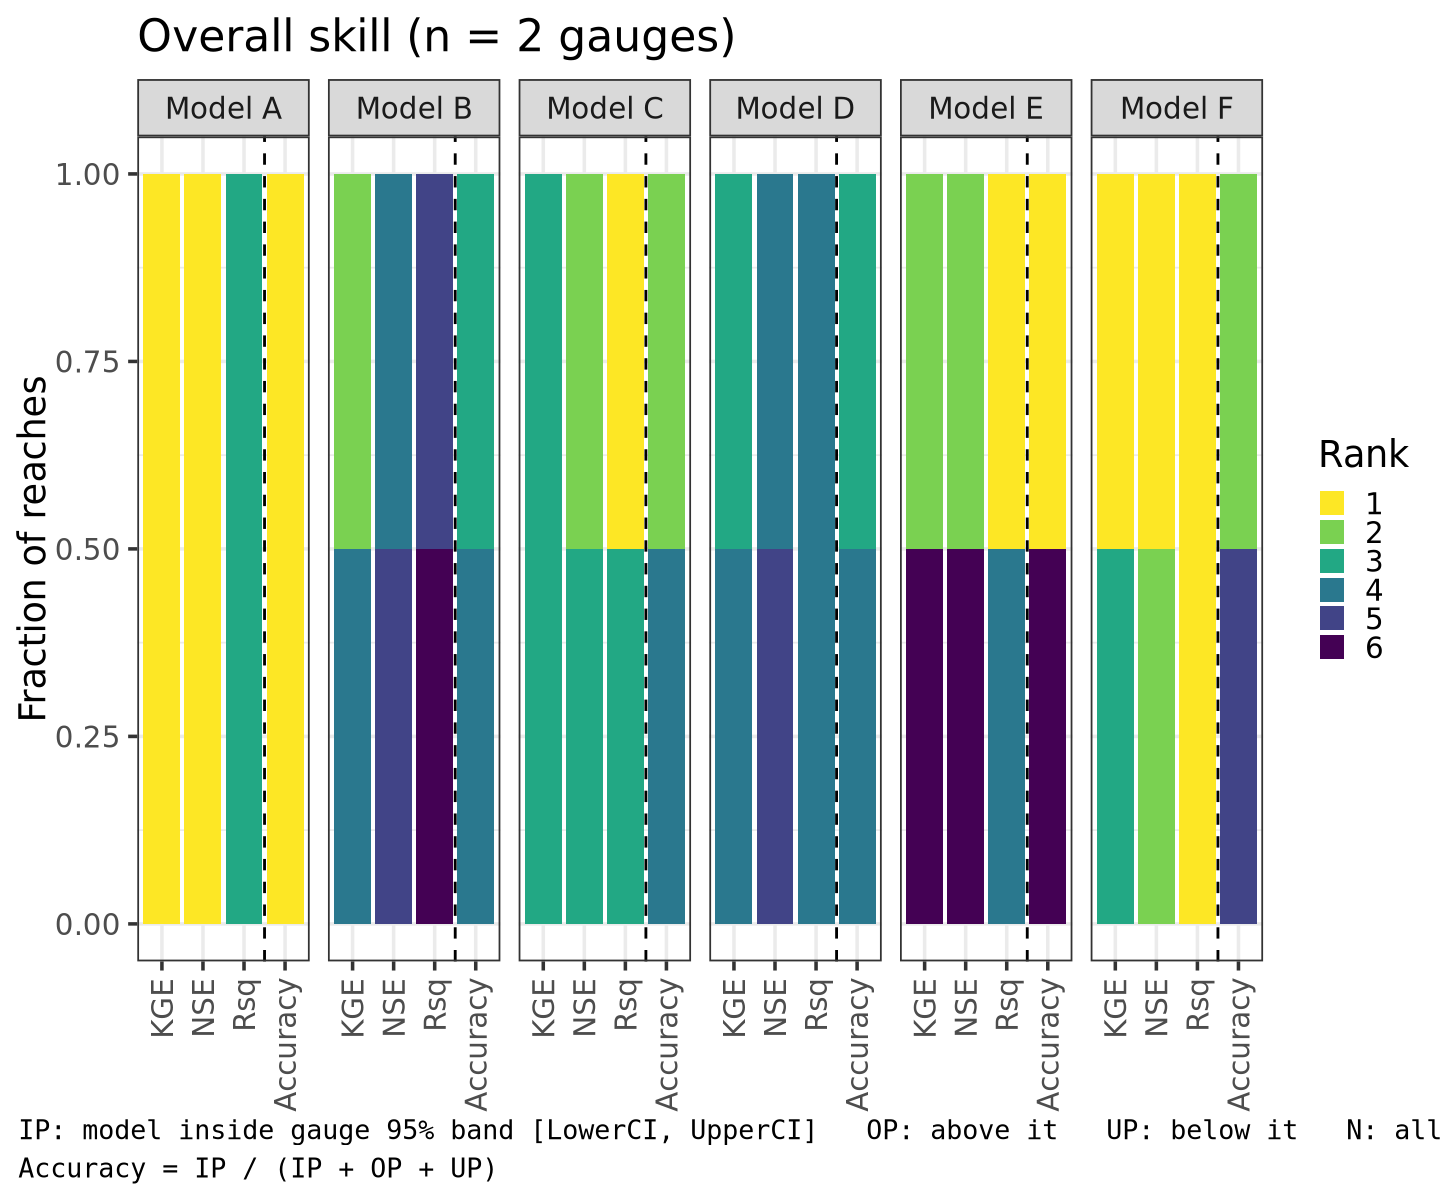

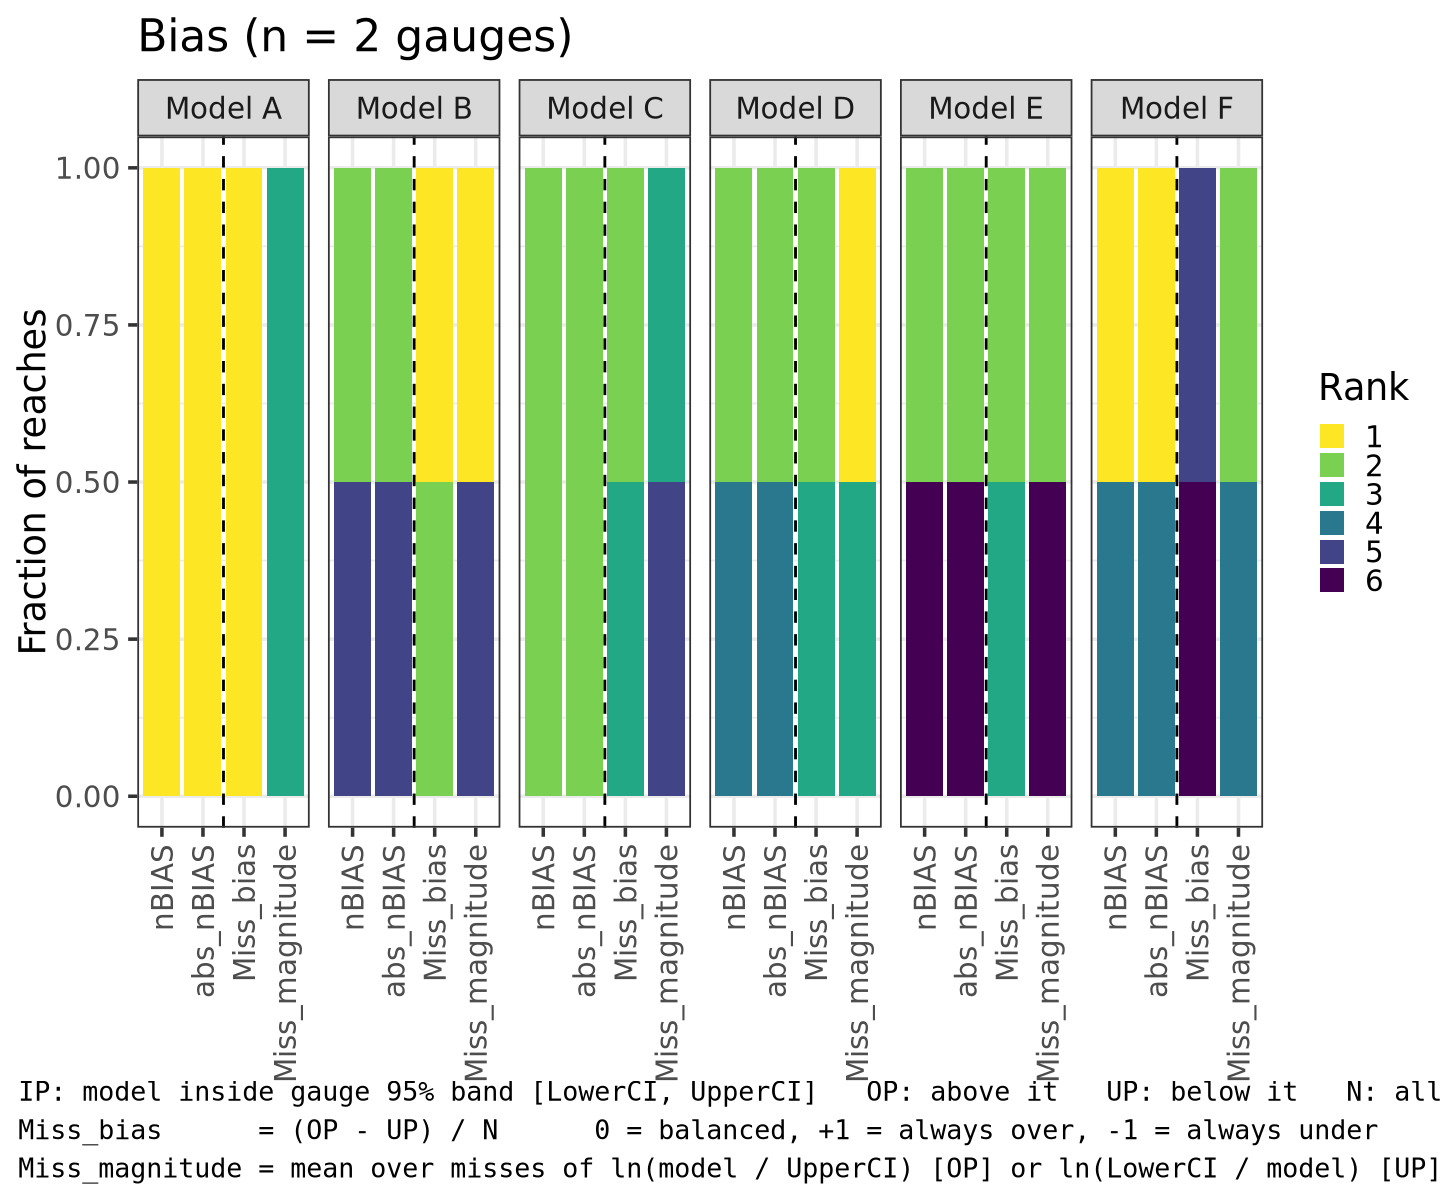

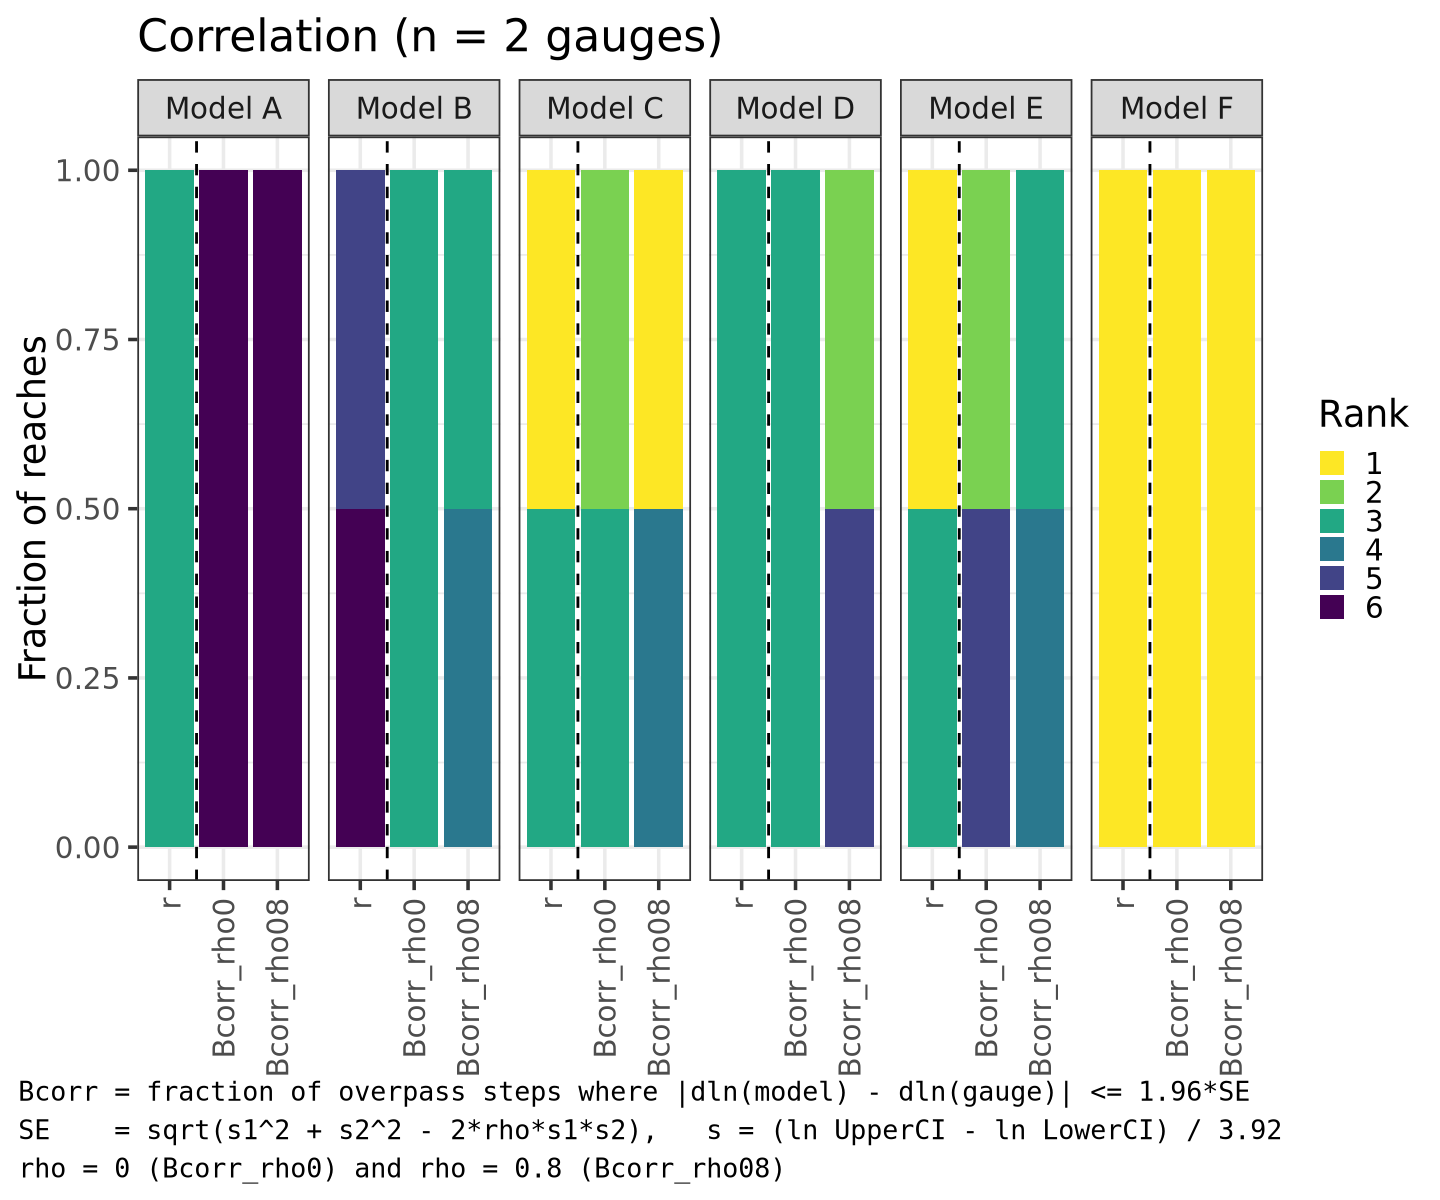

In [21]:
source('/nas/cee-water/cjgleason/colin/Batesian_Validation/make_rank_figs.R', print.eval=TRUE)

Warning message in scale_x_datetime():
“A <numeric> value was passed to a Datetime scale.
ℹ The value was converted to a <POSIXct> object.”
Warning message in scale_x_datetime():
“A <numeric> value was passed to a Datetime scale.
ℹ The value was converted to a <POSIXct> object.”


reach_id,USGS_ID,model,r,Rsq,NSE,KGE,RMSE,nRMSE,nBIAS,abs_nBIAS,Accuracy,Miss_bias,Miss_magnitude,Bcorr_rho0,Bcorr_rho08
<chr>,<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
73114001311,USGS-01048000,F,0.9846794,0.9695936,0.9137650,0.7479480,9.588392,0.2953983,-0.01211782,0.01211782,0.7419355,0.2580645,0.7074540,0.9000000,0.6000000
73140800011,USGS-01318500,F,0.9707259,0.9423088,0.7959561,0.6368218,36.879263,0.4081917,0.32524350,0.32524350,0.3636364,0.6363636,0.4528416,0.8623853,0.5321101


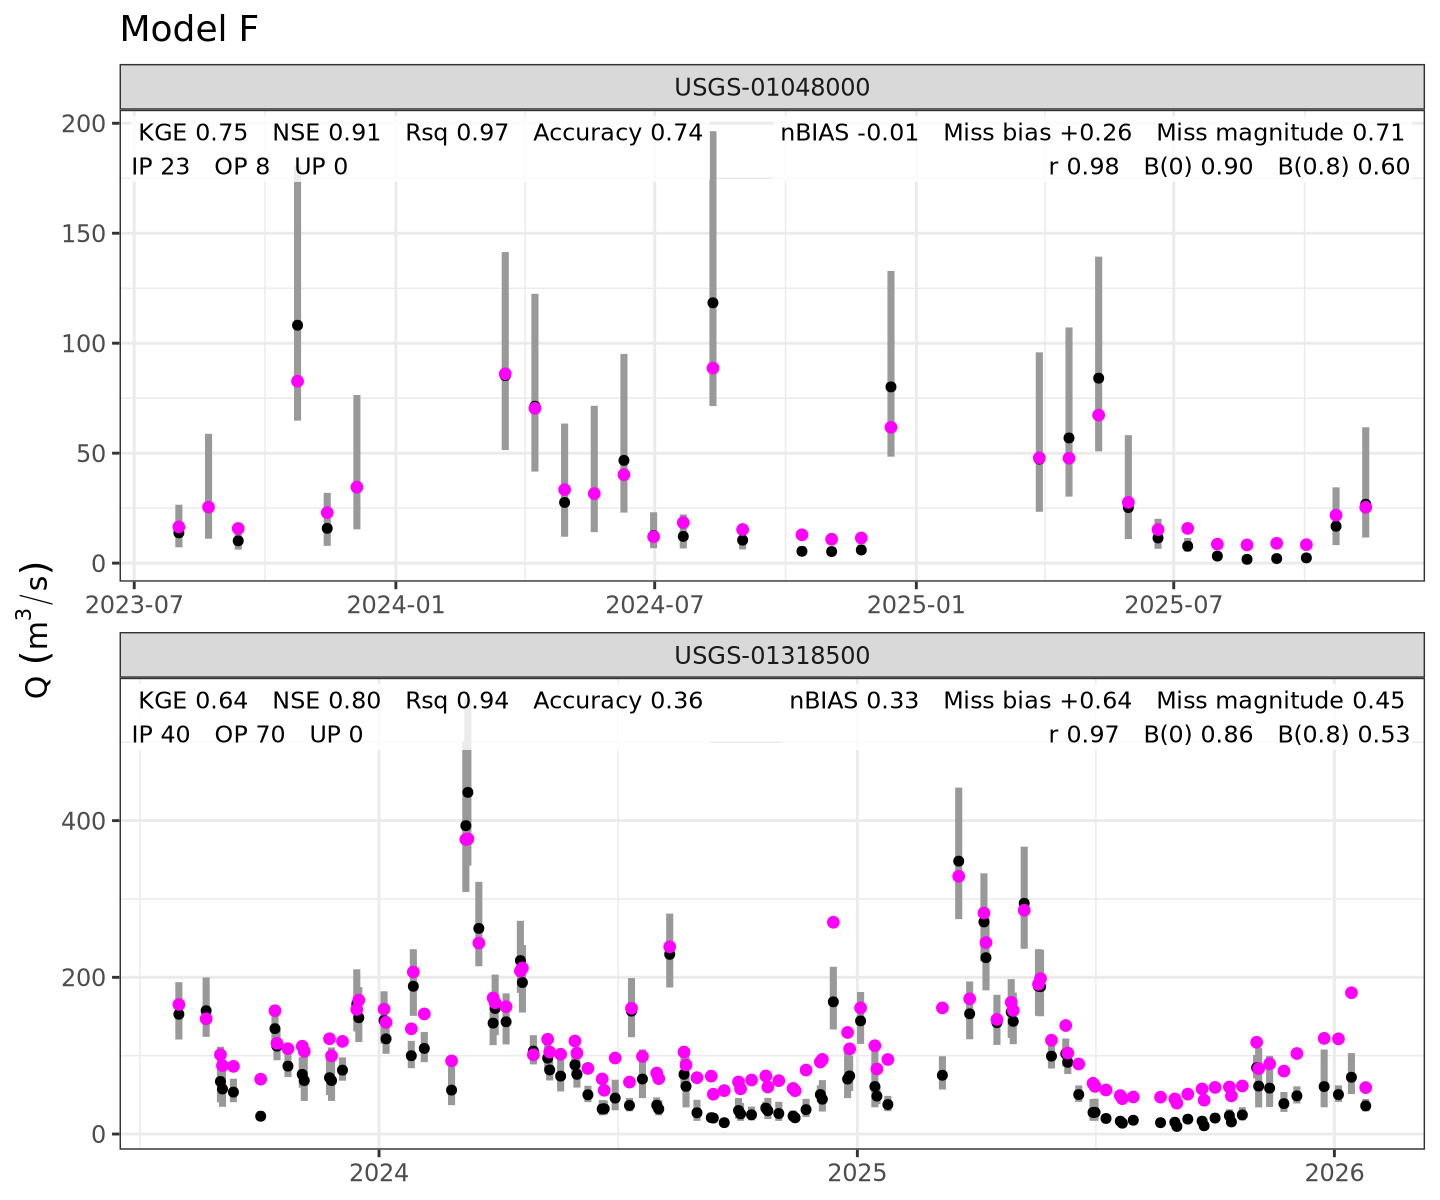

In [19]:
model_letter <- "F"
model_algo   <- algo_key$algo[algo_key$model == model_letter]

pairs_df <- sos_approvedQ_15min %>%
  select(USGS_ID, time, Q_approved, Q_lower, Q_upper, Q_model = all_of(model_algo)) %>%
  filter(!is.na(Q_model), !is.na(Q_approved))

counts <- pairs_df %>%
  filter(!is.na(Q_lower), !is.na(Q_upper)) %>%
  group_by(USGS_ID) %>%
  summarise(IP = sum(Q_model >= Q_lower & Q_model <= Q_upper),
            OP = sum(Q_model > Q_upper),
            UP = sum(Q_model < Q_lower),
            .groups = "drop")

stat_labels <- sos_val_approvedQ_15min %>%
  filter(algo == model_algo) %>%
  select(USGS_ID, KGE, NSE, Rsq, Accuracy) %>%
  left_join(counts, by = "USGS_ID", relationship = "one-to-one") %>%
  mutate(label = sprintf("KGE %.2f   NSE %.2f   Rsq %.2f   Accuracy %.2f\nIP %d   OP %d   UP %d",
                         KGE, NSE, Rsq, Accuracy, IP, OP, UP))

stat_labels_right <- sos_val_approvedQ_15min %>%
  filter(algo == model_algo) %>%
  mutate(label = sprintf("nBIAS %.2f   Miss bias %+.2f   Miss magnitude %.2f\nr %.2f   B(0) %.2f   B(0.8) %.2f",
                         nBIAS, Miss_bias, Miss_magnitude, r, Bcorr_rho0, Bcorr_rho08))

ggplot(pairs_df, aes(time)) +
  geom_linerange(aes(ymin = Q_lower, ymax = Q_upper), colour = "grey60", linewidth = 2) +
  geom_point(aes(y = Q_approved), colour = "black", size = 2) +
  geom_point(aes(y = Q_model), colour = "magenta", size = 2.5) +
  facet_wrap(~ USGS_ID, ncol = 1, scales = "free") +
  labs(title = paste("Model", model_letter), x = NULL, y = expression(Q~(m^3/s))) +
  theme_bw(base_size = 18)+
  geom_label(data = stat_labels, aes(x = -Inf, y = Inf, label = label),
             hjust = -0.02, vjust = 1.1, size = 5, label.size = 0, fill = alpha("white", 0.8)) +
  geom_label(data = stat_labels_right, aes(x = Inf, y = Inf, label = label),
             hjust = 1.02, vjust = 1.1, size = 5, label.size = 0, fill = alpha("white", 0.8)) 

sos_val_approvedQ_15min %>%
  filter(algo == model_algo) %>%
  mutate(model = model_letter, .after = USGS_ID) %>%
  select(-algo, -type)

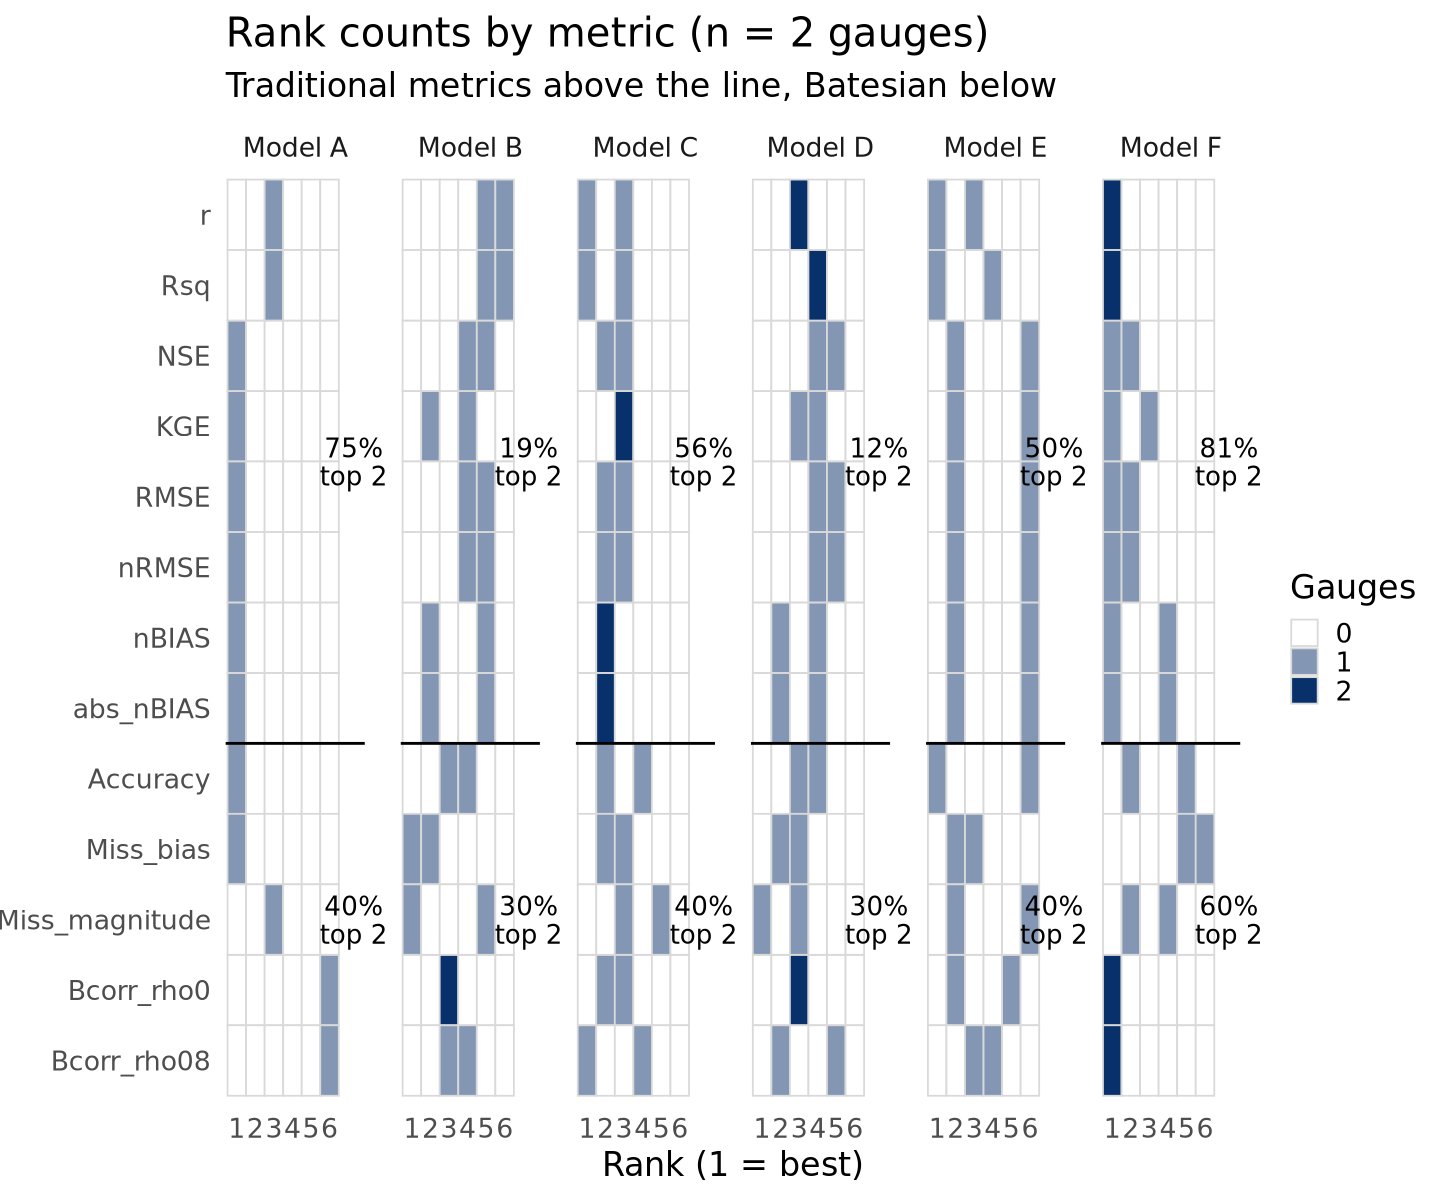

In [23]:
trad_order  <- c("r", "Rsq", "NSE", "KGE", "RMSE", "nRMSE", "nBIAS", "abs_nBIAS")
bates_order <- c("Accuracy", "Miss_bias", "Miss_magnitude", "Bcorr_rho0", "Bcorr_rho08")

ranked <- sos_rank_approvedQ_15min %>%
  filter(!is.na(rank)) %>%
  left_join(algo_key, by = "algo", relationship = "many-to-one") %>%
  mutate(family = if_else(metric %in% bates_order, "Batesian", "Trad"))

rank_counts <- ranked %>%
  count(model, metric, rank) %>%
  complete(model, metric, rank = seq_len(n_algo), fill = list(n = 0)) %>%
  mutate(metric = factor(metric, levels = rev(c(trad_order, bates_order))),
         rank   = factor(rank, levels = seq_len(n_algo)),
         n      = factor(n, levels = 0:max(n)))

# share of gauge x metric rankings at rank 1 or 2, per model and family
top2 <- ranked %>%
  group_by(model, family) %>%
  summarise(pct = 100 * mean(rank <= 2), .groups = "drop") %>%
  mutate(y     = if_else(family == "Trad",
                         length(bates_order) + length(trad_order) / 2 + 0.5,
                         length(bates_order) / 2 + 0.5),
         label = sprintf("%.0f%%\ntop 2", pct))

n_gauges  <- n_distinct(sos_rank_approvedQ_15min$USGS_ID)
fill_cols <- setNames(colorRampPalette(c("white", "#08306b"))(nlevels(rank_counts$n)),
                      levels(rank_counts$n))

ggplot(rank_counts, aes(x = rank, y = metric, fill = n)) +
  geom_tile(colour = "grey85", linewidth = 0.5) +
  geom_hline(yintercept = length(bates_order) + 0.5, linewidth = 0.8) +
  geom_text(data = top2, aes(x = n_algo + 1.3, y = y, label = label), inherit.aes = FALSE,
            size = 5.5, lineheight = 0.9) +
  facet_wrap(~ model, nrow = 1, labeller = labeller(model = function(x) paste("Model", x))) +
  scale_fill_manual(values = fill_cols, name = "Gauges") +
  scale_x_discrete(expand = expansion(add = c(0.6, 1.9))) +
  coord_cartesian(clip = "off") +
  labs(title = paste0("Rank counts by metric (n = ", n_gauges, " gauges)"),
       subtitle = "Traditional metrics above the line, Batesian below",
       x = "Rank (1 = best)", y = NULL) +
  theme_minimal(base_size = 20) +
  theme(panel.grid = element_blank(), panel.spacing = unit(1.5, "lines"))

In [11]:
list.files('/nas/cee-water/cjgleason/heejin/SWOT_Confluence/run-confluence/confluence_RF_consensus/RF_consensus_mnt/output_bugfix/sos/')

[1] "af_sword_v17_SOS_results_20230405T210420_20260912T173206_20261001T192749.nc"
[2] "as_sword_v17_SOS_results_20230329T023256_20260912T214456_20261001T192749.nc"
[3] "eu_sword_v17_SOS_results_20230329T002234_20260912T194112_20261001T192749.nc"
[4] "na_sword_v17_SOS_results_20230329T052824_20260913T144541_20261001T192749.nc"
[5] "oc_sword_v17_SOS_results_20230329T011248_20260913T202524_20261001T192749.nc"
[6] "sa_sword_v17_SOS_results_20230329T032758_20260912T224526_20261001T192749.nc"

In [12]:
test=open.nc(list.files('/nas/cee-water/cjgleason/heejin/SWOT_Confluence/run-confluence/confluence_RF_consensus/RF_consensus_mnt/output_bugfix/sos/',full.names=TRUE)[6])

[1] 104

[1] 104

[1] 72

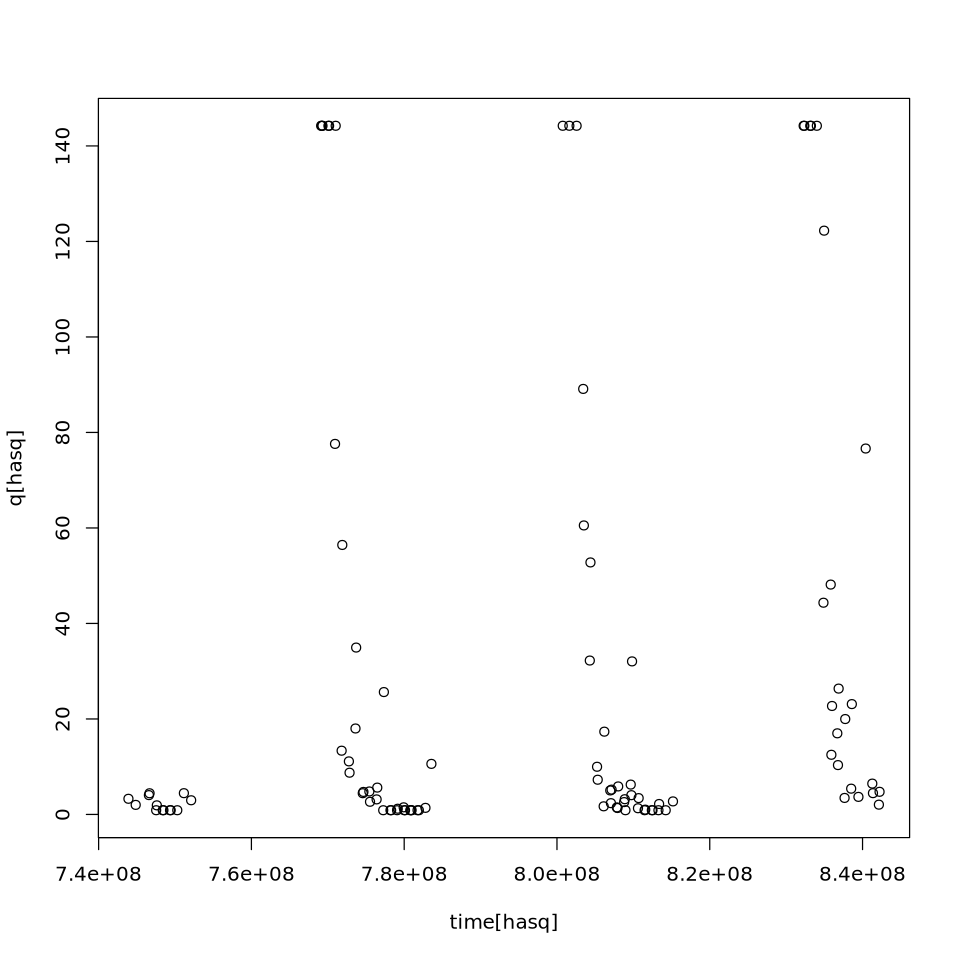

In [13]:
reach_id <- "81390900161"
swot_file <- paste0("/nas/cee-water/cjgleason/heejin/SWOT_Confluence/run-confluence/confluence_RF_consensus/RF_consensus_mnt/flpe/busboi/", reach_id, "_busboi.nc")
swot_nc   <- open.nc(swot_file)
busboi=read.nc(swot_nc,recursive=TRUE)
close.nc(swot_nc)

time=busboi$time
q=busboi$q$q
hasq=!is.na(q)

options(repr.plot.width = 8, repr.plot.height = 8)
length(time[hasq])
length(unique(time[hasq]))
length(unique(q[hasq]))
par(bg = "white")
plot(time[hasq],q[hasq])


[1] 104

[1] 104

[1] 72


  0.887012 144.222094   1.008372   1.201211   1.302737 
        23         14          1          1          1 

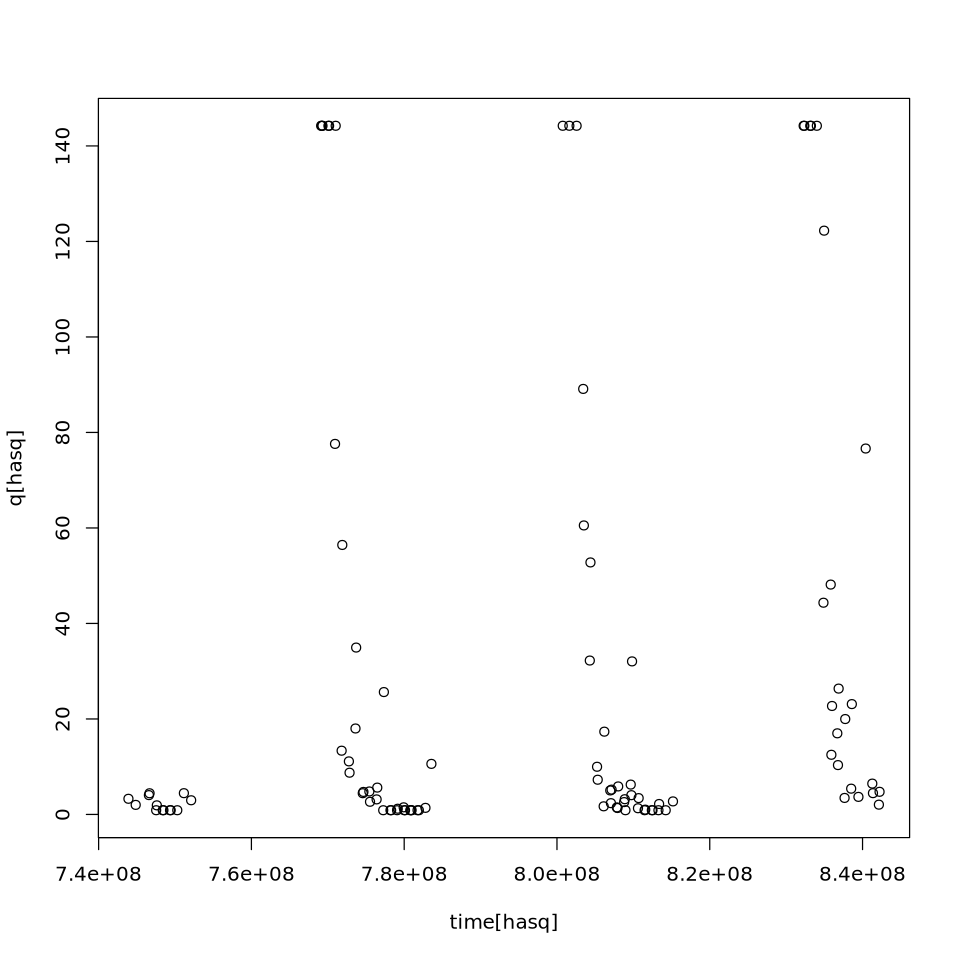

In [14]:
library(RNetCDF)


reach_id <- "81390900161"
sos_file <- "/nas/cee-water/cjgleason/heejin/SWOT_Confluence/run-confluence/confluence_RF_consensus/RF_consensus_mnt/output_new/sos/na_sword_v17_SOS_results_20230329T052824_20260913T144541_20260925T141658.nc"

sos_nc      <- open.nc(sos_file)
reaches_grp <- grp.inq.nc(sos_nc, "reaches")$self
busboi_grp  <- grp.inq.nc(sos_nc, "busboi")$self

idx  <- which(var.get.nc(reaches_grp, "reach_id") == as.numeric(reach_id))
q    <- var.get.nc(busboi_grp, "q",    start = idx, count = 1)[[1]]
time <- var.get.nc(busboi_grp, "time", start = idx, count = 1)[[1]]
close.nc(sos_nc)

hasq <- !is.na(q) & q != -999999999999
length(time[hasq])
length(unique(time[hasq]))
length(unique(q[hasq]))
head(sort(table(round(q[hasq], 6)), decreasing = TRUE), 5)
par(bg = "white")
plot(time[hasq], q[hasq])

day,q
<dttm>,<dbl>
2024-06-16,1.500095e+01
2024-06-17,5.691830e+01
2024-06-17,-1.000000e+12
2024-06-18,-1.000000e+12
2024-06-27,1.115516e+01
2024-06-27,-1.000000e+12
2024-06-28,9.975023e+00
2024-06-28,-1.000000e+12


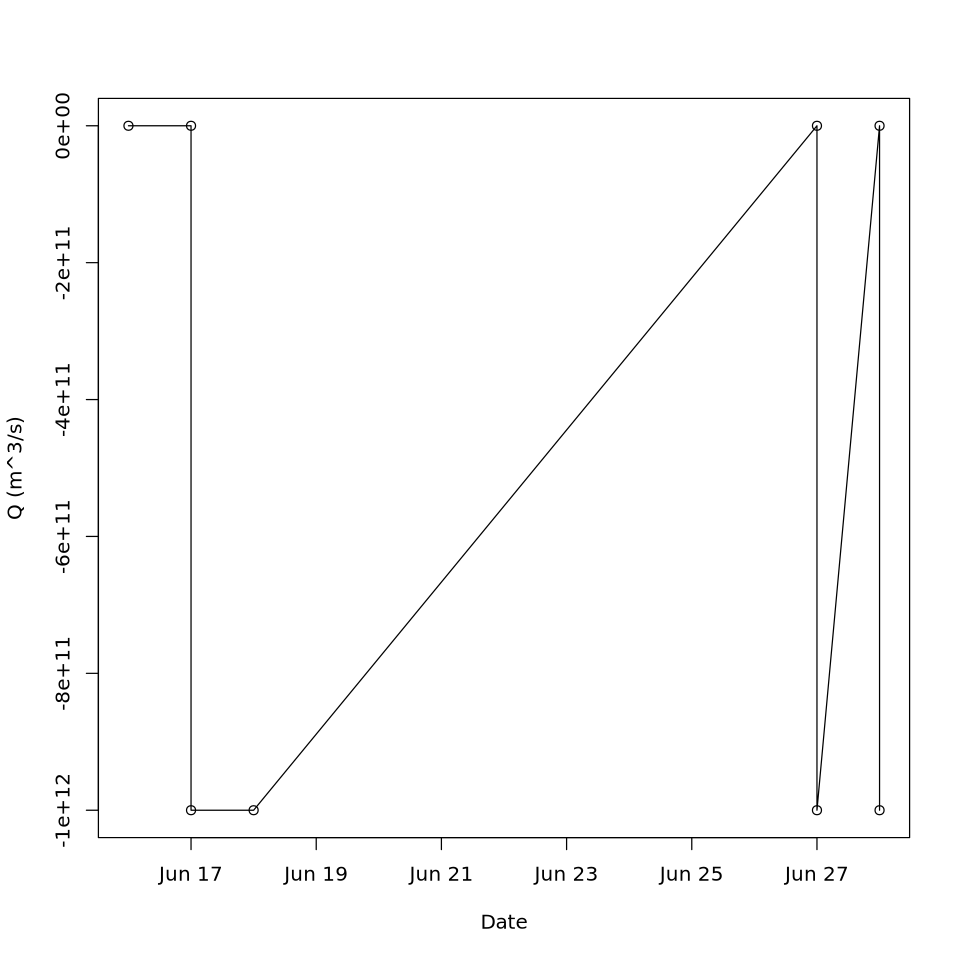

In [15]:
library(RNetCDF)
reach_id <- "81390900161"
sos_file <- "/nas/cee-ice/data/Confluence_Runs/V4_UATtest/na_sword_v17_SOS_results_20230329T052824_20260514T101601_20260519T090824.nc"
sos_nc      <- open.nc(sos_file)
reaches_grp <- grp.inq.nc(sos_nc, "reaches")$self
busboi_grp  <- grp.inq.nc(sos_nc, "busboi")$self

idx  <- which(var.get.nc(reaches_grp, "reach_id") == as.numeric(reach_id))
q    <- var.get.nc(busboi_grp, "q",    start = idx, count = 1)[[1]]
time <- var.get.nc(busboi_grp, "time", start = idx, count = 1)[[1]]
swot_time <- var.get.nc(reaches_grp, "time", start = idx, count = 1)[[1]]
close.nc(sos_nc)

hasq <- !is.na(q) & q != -999999999999

busboi_date<- as.POSIXct(as.POSIXct(time, origin = "2000-01-01", tz = "UTC"))
swot_date <- as.POSIXct(swot_time, origin = "2000-01-01", tz = "UTC")


win <- busboi_date >= as.POSIXct("2024-06-16") & busboi_date <= as.POSIXct("2024-06-28")




par(bg = "white")
plot(busboi_date[win], q[win], type = "o", xlab = "Date", ylab = "Q (m^3/s)")

data.frame(day = busboi_date[win], q = q[win])


In [16]:
sos_nc      <- open.nc(sos_file)
reaches_grp <- grp.inq.nc(sos_nc, "reaches")$self

var.get.nc(reaches_grp, "x",          start = idx, count = 1)  # longitude
var.get.nc(reaches_grp, "y",          start = idx, count = 1)  # latitude
var.get.nc(reaches_grp, "river_name", start = idx, count = 1)
close.nc(sos_nc)

[1] -144.183

[1] 69.72826

[1] "Hulahula Riverr"

In [17]:
sos_nc      <- open.nc(sos_file)
reaches_grp <- grp.inq.nc(sos_nc, "reaches")$self

obs <- var.get.nc(reaches_grp, "observations", start = idx, count = 1)
close.nc(sos_nc)

cycle <- sub("_.*", "", trimws(strsplit(obs, ",")[[1]]))
table(cycle)
table(table(cycle))

cycle
 1 10 11 12 13 14 15 16 17 18 19  2 20 21 22 23 24 25 26 27 28 29  3 30 31 32 
 6  7  8  6  4  8  8  8  8  8  8  4  8  8  8  8  7  8  8  8  8  8  8  8  8  8 
33 34 35 36 37 38 39  4 40 41 42 43 44 45 46 47 48 49  5  6  7  8  9 
 8  8  8  8  8  7  8  8  8  8  8  7  8  8  8  8  8  8  8  8  8  6  7 


 4  6  7  8 
 2  3  5 39 